# Model Comparison Framework

A small, reusable setup for testing many models against a baseline under the same conditions.

**The framework is three pieces:**
1. **`pipe(model, scale=...)`** wraps any estimator in the same preprocessing, so every model sees identical features.
2. **`models = {...}`**: a dictionary of name → pipeline. **Adding a model is one line.**
3. **`compare(models, X, y, cv, scoring)`** cross-validates every model on the **same folds** and returns one table: each metric's mean, plus the spread, the train−validation gap and the fit time.

**Workflow:** baseline → simple models → complex models → compare → tune the top 2–3 → score the winner once on the test set.

Part A runs it on classification (Titanic). Part B reuses the same functions for regression (House Prices).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold, StratifiedKFold

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(10, 4))

## The framework
`scale=True` is for models that need scaled features (linear, k-NN, SVM, MLP). Tree models get `scale=False`.

In [2]:
def pipe(model, scale=True):
    """Same preprocessing for every model: impute (+ scale) numerics, impute + one-hot categoricals."""
    numeric = [SimpleImputer(strategy="median")] + ([StandardScaler()] if scale else [])
    preprocess = ColumnTransformer([
        ("num", make_pipeline(*numeric), make_column_selector(dtype_include="number")),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
         make_column_selector(dtype_include=["object", "category"])),
    ])
    return make_pipeline(preprocess, model)


def compare(models, X, y, cv, scoring):
    """Cross-validate every model on the same folds. Returns (summary table, per-fold scores of the first metric)."""
    rows, folds = {}, {}
    for name, model in models.items():
        res = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True)
        row = {}
        for metric in scoring:
            sign = -1 if metric.startswith("neg_") else 1            # sklearn negates error metrics
            label = metric.removeprefix("neg_")
            row[label] = sign * res[f"test_{metric}"].mean()
        main = scoring[0]
        sign = -1 if main.startswith("neg_") else 1
        row["std"] = res[f"test_{main}"].std()
        row["train-valid gap"] = res[f"train_{main}"].mean() - res[f"test_{main}"].mean()   # > 0 means overfitting
        row["fit time (s)"] = res["fit_time"].mean()
        rows[name] = row
        folds[name] = sign * res[f"test_{main}"]
    return pd.DataFrame(rows).T, pd.DataFrame(folds)


def plot_folds(folds, title):
    """Box plot of per-fold scores. Overlapping boxes mean the difference is probably noise."""
    order = folds.mean().sort_values().index
    ax = folds[order].plot.box(vert=False, figsize=(9, 0.45 * len(order) + 1.5))
    ax.set_title(title)
    return ax

---
# Part A · Classification (Titanic)

In [3]:
titanic = fetch_openml("titanic", version=1, as_frame=True).frame
X = titanic[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]
y = titanic["survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # fixed folds → fair comparison
scoring = ["roc_auc", "accuracy", "f1", "neg_log_loss"]          # first metric = the one you rank by

## Step 1 · Baseline
Every model has to beat this. If one doesn't, something is wrong with it or with the features.

In [4]:
from sklearn.dummy import DummyClassifier

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Baseline (stratified)": DummyClassifier(strategy="stratified", random_state=0),
}
results, folds = compare(models, X_train, y_train, cv, scoring)
results.round(3)

,roc_auc,accuracy,f1,log_loss,std,train-valid gap,fit time (s)
Baseline (majority),0.500,0.618,0.000,13.770,0.000,0.000,0.0
Baseline (stratified),0.504,0.537,0.377,16.697,0.041,0.002,0.0


## Step 2 · Add models (one line each)
Go from simple to complex. The linear model is the bar that the non-linear models need to clear.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

models.update({
    "Logistic regression": pipe(LogisticRegression(max_iter=1000)),
    "k-NN":                pipe(KNeighborsClassifier(n_neighbors=15)),
    "Decision tree":       pipe(DecisionTreeClassifier(max_depth=4, random_state=0), scale=False),
    "Random forest":       pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=0), scale=False),
    "Extra trees":         pipe(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, random_state=0), scale=False),
    "Hist grad boosting":  pipe(HistGradientBoostingClassifier(random_state=0), scale=False),
    "XGBoost":             pipe(XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4), scale=False),
    "SVM (RBF)":           pipe(SVC(probability=True, random_state=0)),
})

## Step 3 · Compare

In [6]:
results, folds = compare(models, X_train, y_train, cv, scoring)
results.sort_values(scoring[0].removeprefix("neg_"), ascending=False).round(3)

,roc_auc,accuracy,f1,log_loss,std,train-valid gap,fit time (s)
Random forest,0.871,0.827,0.754,0.428,0.020,0.081,0.192
XGBoost,0.863,0.819,0.745,0.442,0.026,0.097,0.226
Extra trees,0.861,0.805,0.714,0.439,0.024,0.048,0.125
Hist grad boosting,0.858,0.813,0.745,0.488,0.027,0.127,0.493
Decision tree,0.851,0.799,0.703,0.792,0.020,0.028,0.004
k-NN,0.847,0.791,0.711,0.707,0.023,0.029,0.004
Logistic regression,0.838,0.785,0.711,0.469,0.014,0.003,0.013
SVM (RBF),0.828,0.806,0.736,0.474,0.026,0.036,0.040
Baseline (stratified),0.504,0.537,0.377,16.697,0.041,0.002,0.000
Baseline (majority),0.500,0.618,0.000,13.770,0.000,0.000,0.000


**How to read the table:**
- **Ranking metric** (first column): the primary choice. The other metrics are a sanity check.
- **std**: if two models differ by less than about one std, treat them as tied.
- **train-valid gap**: a large gap means the model overfits, so regularize it before tuning anything else.
- **fit time**: if two models tie, prefer the faster and simpler one.

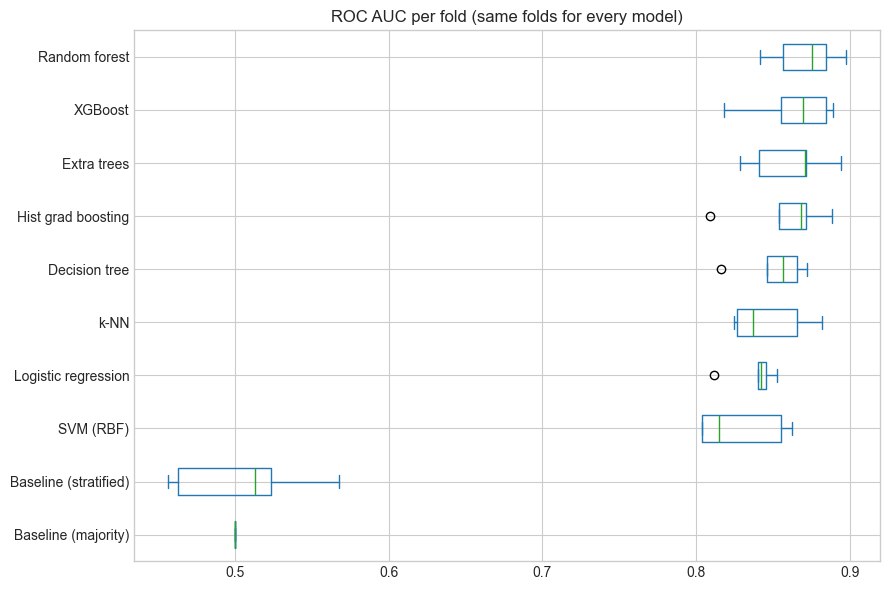

In [7]:
plot_folds(folds, "ROC AUC per fold (same folds for every model)");

## Step 4 · Add a model later without rerunning everything
Run `compare` on just the new entries, then `pd.concat` onto the results so far.

In [8]:
from sklearn.neural_network import MLPClassifier

new = {"MLP": pipe(MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-2, max_iter=2000, random_state=0))}
new_results, new_folds = compare(new, X_train, y_train, cv, scoring)

models.update(new)
results = pd.concat([results, new_results])
folds = pd.concat([folds, new_folds], axis=1)
results.sort_values("roc_auc", ascending=False).round(3).head()

,roc_auc,accuracy,f1,log_loss,std,train-valid gap,fit time (s)
Random forest,0.871,0.827,0.754,0.428,0.020,0.081,0.192
XGBoost,0.863,0.819,0.745,0.442,0.026,0.097,0.226
Extra trees,0.861,0.805,0.714,0.439,0.024,0.048,0.125
Hist grad boosting,0.858,0.813,0.745,0.488,0.027,0.127,0.493
MLP,0.856,0.807,0.723,0.456,0.023,0.031,0.280


## Step 5 · Tune the top contenders
Keep one grid per model name. Grid keys follow the pipeline step names, and the model step is the lower-cased class name.
Tune only the top 2–3. Tuning everything takes a long time and rarely changes the ranking. Top models without a grid entry are skipped.

In [9]:
grids = {
    "Logistic regression": {"logisticregression__C": [0.01, 0.1, 1, 10]},
    "Random forest":       {"randomforestclassifier__max_features": ["sqrt", 0.5],
                            "randomforestclassifier__min_samples_leaf": [1, 3, 5]},
    "Hist grad boosting":  {"histgradientboostingclassifier__learning_rate": [0.03, 0.1],
                            "histgradientboostingclassifier__max_depth": [3, None]},
    "XGBoost":             {"xgbclassifier__max_depth": [3, 5],
                            "xgbclassifier__learning_rate": [0.03, 0.1]},
}

top = results.drop(index=[n for n in results.index if n.startswith("Baseline")]) \
             .sort_values("roc_auc", ascending=False).index[:3]

tuned = {}
for name in top:
    if name in grids:
        search = GridSearchCV(models[name], grids[name], cv=cv, scoring=scoring[0]).fit(X_train, y_train)
        tuned[f"{name} (tuned)"] = search.best_estimator_
        print(f"{name:22s} {search.best_score_:.4f}  {search.best_params_}")

Random forest          0.8713  {'randomforestclassifier__max_features': 0.5, 'randomforestclassifier__min_samples_leaf': 3}


XGBoost                0.8644  {'xgbclassifier__learning_rate': 0.03, 'xgbclassifier__max_depth': 5}


In [10]:
tuned_results, tuned_folds = compare(tuned, X_train, y_train, cv, scoring)
pd.concat([results.loc[top], tuned_results]).sort_values("roc_auc", ascending=False).round(3)

,roc_auc,accuracy,f1,log_loss,std,train-valid gap,fit time (s)
Random forest (tuned),0.871,0.831,0.761,0.435,0.025,0.090,0.216
Random forest,0.871,0.827,0.754,0.428,0.020,0.081,0.192
XGBoost (tuned),0.864,0.816,0.742,0.438,0.021,0.095,0.262
XGBoost,0.863,0.819,0.745,0.442,0.026,0.097,0.226
Extra trees,0.861,0.805,0.714,0.439,0.024,0.048,0.125


## Step 6 · Score the winner on the test set, once

In [11]:
from sklearn.metrics import get_scorer

candidates = {**models, **tuned}
best_name = pd.concat([results, tuned_results])["roc_auc"].idxmax()
best = candidates[best_name].fit(X_train, y_train)

test_scores = {m.removeprefix("neg_"): abs(get_scorer(m)(best, X_test, y_test)) for m in scoring}
baseline = models["Baseline (majority)"].fit(X_train, y_train)
base_scores = {m.removeprefix("neg_"): abs(get_scorer(m)(baseline, X_test, y_test)) for m in scoring}

pd.DataFrame({best_name: test_scores, "Baseline (majority)": base_scores}).T.round(3)

,roc_auc,accuracy,f1,log_loss
Random forest (tuned),0.864,0.824,0.736,0.442
Baseline (majority),0.500,0.618,0.000,13.757


---
# Part B · Regression (House Prices): the same framework, different models and metrics
Only three things change: the **models**, the **scoring list** and the **CV splitter**. `pipe`, `compare` and `plot_folds` are reused unchanged.
The model is fit on `log1p(SalePrice)`, so RMSE here equals the competition's RMSLE.

In [12]:
houses = fetch_openml(name="house_prices", as_frame=True).frame
X = houses.drop(columns=["Id", "SalePrice"])
y = np.log1p(houses["SalePrice"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

cv = KFold(n_splits=5, shuffle=True, random_state=0)
scoring = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, LassoCV, ElasticNetCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

models = {
    "Baseline (mean)":    DummyRegressor(strategy="mean"),
    "Baseline (median)":  DummyRegressor(strategy="median"),
    "OLS":                pipe(LinearRegression()),
    "Ridge":              pipe(Ridge(alpha=10)),
    "Lasso":              pipe(LassoCV(cv=5, max_iter=5000)),
    "Elastic net":        pipe(ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], cv=5, max_iter=5000)),
    "k-NN":               pipe(KNeighborsRegressor(n_neighbors=10)),
    "Random forest":      pipe(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0), scale=False),
    "Hist grad boosting": pipe(HistGradientBoostingRegressor(random_state=0), scale=False),
    "XGBoost":            pipe(XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8), scale=False),
    "SVR (RBF)":          pipe(SVR(C=1.0, epsilon=0.05)),
}

results, folds = compare(models, X_train, y_train, cv, scoring)
results.sort_values("root_mean_squared_error").round(4)

,root_mean_squared_error,mean_absolute_error,r2,std,train-valid gap,fit time (s)
Lasso,0.1254,0.0817,0.9003,0.0204,0.0294,0.1847
Elastic net,0.1261,0.0820,0.8992,0.0202,0.0304,0.4125
XGBoost,0.1279,0.0857,0.8975,0.0137,0.1009,0.5233
Ridge,0.1292,0.0843,0.8945,0.0191,0.0287,0.0134
SVR (RBF),0.1366,0.0873,0.8832,0.0113,0.0804,0.0485
Hist grad boosting,0.1380,0.0936,0.8805,0.0131,0.0958,0.8924
OLS,0.1401,0.0912,0.8766,0.0182,0.0567,0.0239
Random forest,0.1454,0.0985,0.8680,0.0109,0.0913,0.8002
k-NN,0.1766,0.1215,0.8045,0.0142,0.0175,0.0132
Baseline (mean),0.4022,0.3118,-0.0064,0.0093,0.0004,0.0005


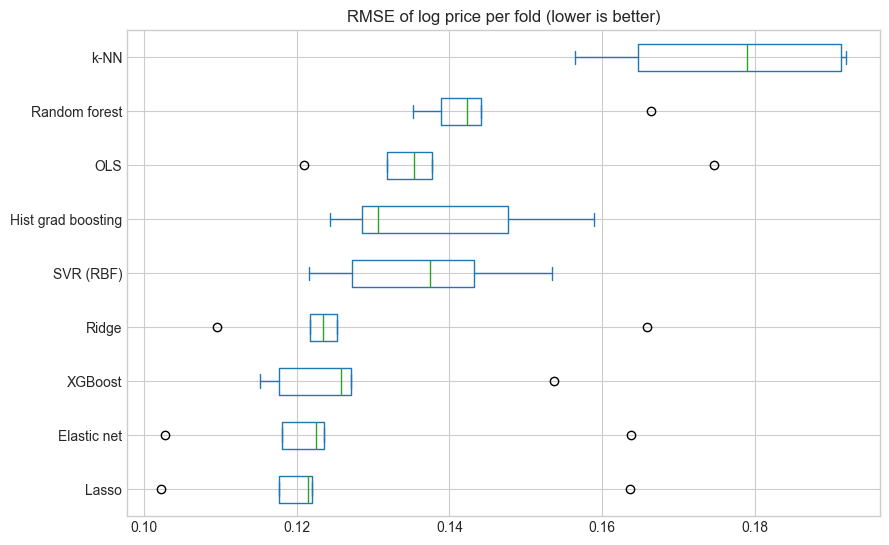

In [14]:
plot_folds(folds.drop(columns=["Baseline (mean)", "Baseline (median)"]), "RMSE of log price per fold (lower is better)");

**Reading this one:**
- The linear models and boosting usually come out close. An **ensemble of two different model types**, such as a simple average of Ridge and boosted trees, often beats both.
- **OLS trails Ridge and Lasso.** With about 250 one-hot columns, many of them rare, its coefficients fit noise, and the penalty fixes that.
- Look at the **train-valid gap**: the tree models fit the training folds almost perfectly. That's normal for forests, and it's a cue to regularize boosting.

## Bonus · Treat an ensemble as just another model
Anything with `fit` and `predict` slots into the framework, including a blend of the winners.

In [15]:
from sklearn.ensemble import VotingRegressor

models["Ridge + XGBoost (avg)"] = VotingRegressor([("ridge", models["Ridge"]), ("xgb", models["XGBoost"])])

blend_results, _ = compare({"Ridge + XGBoost (avg)": models["Ridge + XGBoost (avg)"]}, X_train, y_train, cv, scoring)
pd.concat([results, blend_results]).sort_values("root_mean_squared_error").round(4).head(5)

,root_mean_squared_error,mean_absolute_error,r2,std,train-valid gap,fit time (s)
Ridge + XGBoost (avg),0.1222,0.0800,0.9058,0.0170,0.0624,0.5384
Lasso,0.1254,0.0817,0.9003,0.0204,0.0294,0.1847
Elastic net,0.1261,0.0820,0.8992,0.0202,0.0304,0.4125
XGBoost,0.1279,0.0857,0.8975,0.0137,0.1009,0.5233
Ridge,0.1292,0.0843,0.8945,0.0191,0.0287,0.0134


**Takeaways**
- **Fix the folds and the preprocessing**, and only the model changes between rows. That's what makes the comparison fair.
- **Start from a baseline.** It sets the floor and catches broken pipelines.
- **Adding a model is one dict entry.** Add a metric by appending to `scoring`. Switch tasks by changing the models, scoring list and CV splitter.
- **Rank by one metric, and check the std, the overfitting gap and the fit time** before declaring a winner.
- **Tune only the top few, and touch the test set once.**